# Fig. 9: considerations for application to a real process (Section 3.5).

Styling follows Figs. 3, 4 and 6-8.
- (a) Within-batch SD of PAA over the 200 evaluation batches (sampled every 12 h of batch time), for no intervention, APC, estimated PAA + BO and PPO; boxplot + stripplot.
- (b)(c) PAA estimators trained on progressively narrower PAA windows of the original training set, plotted against the spread of the training labels (sigma, same quantity as cal_std in Fig. 1). Raman PLS (Fig. 1, e4_unified.json), Patch Transformer (w68_win*_s*.json; point = mean over 3 seeds, bar = min-max) and on-line-channel PLS (w74_pls_win*.json, deterministic). (b) Predicted PAA at a true PAA of 2,400 mg/L.  (c) RMSEP (left axis) and R^2 (right axis).
- (d) pyIndPenSim yield over 100 validation batches for each controller (no intervention, APC, estimated PAA + BO, PPO) and variant (original; retrained on its own operating records; retrained with 10/20/30 % perturbation).

In [1]:
import sys; sys.path.insert(0, '..')          # repository root, for paths.py
from paths import DATA, OUTD                   # data/ and output/

In [2]:
import json, numpy as np, matplotlib; matplotlib.use('Agg')
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
G = DATA; R = DATA; OUT = OUTD + 'fig9'
INK, GRY = '#23201a', '#8f897d'; C_APC, C_BO, C_PPO, C_TOX = '#8a3324', '#2a7f7a', '#c9a227', '#a35a3c'
plt.rcParams.update({'font.family': ['DejaVu Sans'], 'font.size': 5.5, 'axes.titlesize': 6.5, 'axes.labelsize': 5.5, 'xtick.labelsize': 5.0,
                     'ytick.labelsize': 5.0, 'axes.linewidth': 0.5, 'xtick.major.width': 0.5, 'ytick.major.width': 0.5,
                     'xtick.major.size': 2, 'ytick.major.size': 2, 'legend.fontsize': 5.0, 'mathtext.default': 'regular'})
def style(a, right=False):
    for sp in ('top',) + (() if right else ('right',)): a.spines[sp].set_visible(False)
    for sp in a.spines.values(): sp.set_color(INK)
    a.tick_params(colors=INK)
def title(a, s): a.set_title(s, loc='left', fontweight='bold', color=INK, pad=4)
fig = plt.figure(figsize=(17 / 2.54, 11 / 2.54), facecolor='white')
gs = GridSpec(2, 2, figure=fig, wspace=0.30, hspace=0.62, left=0.08, right=0.93, top=0.94, bottom=0.19)
rng = np.random.default_rng(0)

In [3]:
# (a)
v = np.load(G + __import__('os').environ.get('TRAJ', 'traj_b5v10.npz')); fr = v['frac']; L = np.load(G + 'testset_fig5_REPORTONLY_random200.npz')['lens'] * 0.2
def get(k):
    a_ = v[f'{k}_PAA']; return np.nanmean(a_.reshape(-1, 200, a_.shape[1]), 0) if a_.shape[0] != 200 else a_
ARMS = [('No\nintervention', 'base', GRY), ('APC', 'apc', C_APC), ('BO-tuned\ncontroller', 'bo', C_BO), ('PPO', 'rl', C_PPO)]
SD = []
for _, k, _ in ARMS:
    A = get(k); s = []
    for j in range(200):
        ts = np.arange(12, L[j], 12); s.append(np.std(np.interp(ts, fr * L[j], A[j]), ddof=1))
    SD.append(np.array(s))
aa = fig.add_subplot(gs[0, 0]); style(aa)
bp = aa.boxplot(SD, positions=range(4), widths=0.5, showfliers=False, patch_artist=True, medianprops=dict(color=INK, lw=0.8),
                whiskerprops=dict(color=INK, lw=0.5), capprops=dict(color=INK, lw=0.5), boxprops=dict(lw=0.5, color=INK))
for b_, (_, _, c) in zip(bp['boxes'], ARMS): b_.set_facecolor('white')
for x, (s, (_, _, c)) in enumerate(zip(SD, ARMS)):
    aa.scatter(x + (rng.random(len(s)) - .5) * 0.32, s, s=1.6, color=c, alpha=.55, lw=0, zorder=3)
aa.set_yscale('log'); aa.set_xticks(range(4)); aa.set_xticklabels([n for n, _, _ in ARMS], color=INK); aa.tick_params(axis='x', length=0)
aa.set_ylabel('PAA variation within a batch, SD (mg L$^{-1}$)', color=INK); title(aa, '(a)')
from matplotlib.ticker import FuncFormatter
aa.yaxis.set_major_formatter(FuncFormatter(lambda y, _: f'{y:g}'))

In [4]:
# (b)(c) Patch Transformer retrained (3 seeds) on the original training set restricted to the windows
#        1,200 +/- w used in Fig. 1(c)(d). x = sigma of the training labels (cal_std in Fig. 1).
#        Raman PLS from Fig. 1 (e4); Patch Transformer: point = seed mean, bar = min-max.
from matplotlib.ticker import FixedLocator
from matplotlib.lines import Line2D
e4 = json.load(open(R + 'e4_unified.json')); rows = e4['curve']; SPT, R2G = e4['SP'], e4['R2_GATE']
sx = np.array([r['cal_std'] for r in rows]); rd = np.array([2400 * (1 + r['bias']['2400']) for r in rows])
r2x = np.array([r['R2'] for r in rows]); rmx = np.array([r['RMSEP'] for r in rows])
WINS = ['3', '5', '8', '12', '18', '26', '38', '55', '80', '120', 'all']
W8 = [[json.load(open(R + f'w68_win{w}_s{s}.json')) for s in range(3)] for w in WINS]
px = np.array([np.mean([d['train_sd'] for d in ws]) for ws in W8])
def arr(k): return np.array([[d[k] for d in ws] for ws in W8])
prd, pr2, prm = arr('read2400'), arr('val_r2'), arr('val_rmse')
W74 = [json.load(open(R + f'w74_pls_win{w}.json')) for w in WINS]                          # PLS on on-line channels (deterministic, single run)
qx, qrd, qr2, qrm = (np.array([d[k] for d in W74]) for k in ('train_sd', 'read2400', 'val_r2', 'val_rmse'))
def logx(a):
    a.set_xscale('log'); a.set_xlim(1, 4000); a.xaxis.set_major_locator(FixedLocator([1, 10, 100, 1000]))
    a.xaxis.set_major_formatter(FuncFormatter(lambda v_, _: f'{v_:g}')); a.xaxis.set_minor_formatter(FuncFormatter(lambda v_, _: ''))
BLU, RUST = '#46618a', '#a35a3c'                                                  # colours as in Fig. 1(c)(d): colour = metric, marker fill = model
LS_P, LS_Q = (0, (4, 1.5)), (0, (5, 1.3, 1, 1.3))                                # Raman PLS = filled marker, solid line (Fig. 1); Patch Transformer = open marker, dashed; on-line PLS = half-filled marker, dash-dot
def curve(a, x, y, c, mk, ms, lo=None, hi=None, patch=False, pls=False, z=4):      # as in Fig. 1, the last (full-range) point is joined with a dotted line
    a.plot(x[:-1], y[:-1], ls=LS_P if patch else (LS_Q if pls else '-'), color=c, lw=0.9, zorder=z); a.plot(x[-2:], y[-2:], ls=(0, (1, 1.2)), color=c, lw=0.8, zorder=z - 1)
    if lo is not None: a.errorbar(x, y, yerr=[y - lo, hi - y], fmt='none', ecolor=c, elinewidth=0.6, capsize=0, zorder=z)
    if pls: a.plot(x, y, ls='', marker=mk, color=c, ms=ms, fillstyle='bottom', mfc=c, mfcalt='white', mec=c, mew=0.6, zorder=z + 1); return
    a.plot(x, y, ls='', marker=mk, color=c, ms=ms, mfc='white' if patch else c, mec=c if patch else 'white', mew=0.7 if patch else 0.5, zorder=z + 1)
LEG = dict(frameon=False, handlelength=1.8, borderaxespad=0.2, labelspacing=0.35)
ab = fig.add_subplot(gs[0, 1]); style(ab)
ab.axhline(2400, color=INK, lw=0.9, zorder=1); ab.axhline(SPT, color=GRY, ls=(0, (3, 2.2)), lw=0.7, zorder=1)
curve(ab, sx, rd, BLU, 'o', 3.2)
curve(ab, px, prd.mean(1), BLU, 'o', 3.2, prd.min(1), prd.max(1), patch=True); curve(ab, qx, qrd, BLU, 'o', 3.2, pls=True)
logx(ab); ab.set_ylim(1000, 2800); ab.set_yticks(range(1000, 2801, 200))
ab.set_xlabel('PAA spread in the training data, $\\sigma$ (mg L$^{-1}$)', color=INK); ab.set_ylabel('Predicted PAA (mg L$^{-1}$)', color=INK)
ab.legend([Line2D([], [], color=INK, lw=0.9), Line2D([], [], color=GRY, ls=(0, (3, 2.2)), lw=0.7),
           Line2D([], [], color=BLU, marker='o', lw=0.9, ms=3.2, mec='white', mew=0.5), Line2D([], [], color=BLU, marker='o', ls=LS_P, lw=0.9, ms=3.2, mfc='white', mec=BLU, mew=0.7),
           Line2D([], [], color=BLU, marker='o', ls=LS_Q, lw=0.9, ms=3.2, fillstyle='bottom', mfc=BLU, mfcalt='white', mec=BLU, mew=0.6)],
          ['True PAA', 'APC set-point', 'Raman PLS', 'Patch Transformer', 'On-line PLS'], loc='upper left', ncol=3, columnspacing=1.2, **LEG)
title(ab, '(b)')
ac = fig.add_subplot(gs[1, 0]); style(ac, right=True); ac2 = ac.twinx(); style(ac2, right=True); ac2.spines['left'].set_visible(False)
ac2.axhline(R2G, color=RUST, ls=(0, (3, 2.2)), lw=0.7, zorder=3)
curve(ac2, sx, r2x, RUST, 'D', 2.8); curve(ac2, px, pr2.mean(1), RUST, 'D', 2.8, pr2.min(1), pr2.max(1), patch=True); curve(ac2, qx, qr2, RUST, 'D', 2.8, pls=True)
curve(ac, sx, rmx, BLU, 'o', 3.2); curve(ac, px, prm.mean(1), BLU, 'o', 3.2, prm.min(1), prm.max(1), patch=True); curve(ac, qx, qrm, BLU, 'o', 3.2, pls=True)
logx(ac); ac.set_ylim(-60, 1400); ac.set_yticks(range(0, 1001, 200)); ac.set_ylabel('RMSEP (mg L$^{-1}$)', color=BLU)
ac.tick_params(axis='y', colors=BLU); ac.spines['left'].set_color(BLU); ac.spines['right'].set_visible(False)
ac2.set_ylim(pr2.min() - .3, 3.2); ac2.set_yticks(range(-4, 2)); ac2.set_ylabel('$R^2$', color=RUST); ac2.tick_params(axis='y', colors=RUST); ac2.spines['right'].set_color(RUST)
ac.set_xlabel('PAA spread in the training data, $\\sigma$ (mg L$^{-1}$)', color=INK)
ac.legend([Line2D([], [], marker='o', color=BLU, lw=0.9, ms=3.2, mec='white', mew=0.5), Line2D([], [], marker='D', color=RUST, lw=0.9, ms=2.8, mec='white', mew=0.5),
           Line2D([], [], color=RUST, ls=(0, (3, 2.2)), lw=0.7), Line2D([], [], color=GRY, ls=(0, (1, 1.2)), lw=0.8),
           Line2D([], [], marker='o', color=INK, lw=0.9, ms=3.2, mec='white', mew=0.5), Line2D([], [], marker='o', color=INK, ls=LS_P, lw=0.9, ms=3.2, mfc='white', mec=INK, mew=0.7),
           Line2D([], [], marker='o', color=INK, ls=LS_Q, lw=0.9, ms=3.2, fillstyle='bottom', mfc=INK, mfcalt='white', mec=INK, mew=0.6)],
          ['RMSEP', '$R^2$', '$R^2$ acceptance', 'Not sampled', 'Raman PLS', 'Patch Transformer', 'On-line PLS'], loc='upper left', ncol=3, columnspacing=1.0, **LEG)
title(ac, '(c)')

In [5]:
# (d) pyIndPenSim yield over 100 validation batches: controller (no intervention, APC, BO, PPO) x variant
#     (original, retrained on its own operating records, perturbation 10/20/30 %).
#     Point = batch, seeds pooled (BO and PPO: 3 seeds x 100; APC perturbed variants: 3 seeds; original and
#     retrained: 1 run). APC uses a different Raman-spectrum random stream (Raman_spec=2), so it is not
#     paired batch-by-batch with no intervention.
A9 = np.load(R + 'w69_apc.npz'); YB = np.load(G + 'dev_bank_200.npz')['ybase'][:100]
def cat(fs): return np.concatenate([np.load(f)[:100] for f in fs])
VAR = ['Original', 'Retrained', '+10 %', '+20 %', '+30 %']
GRP = [('No\nintervention', GRY, [YB]),
       ('APC', C_APC, [A9['orig|0'], A9['rt|0']] + [np.concatenate([A9[f'p{q}|{k}'] for k in range(3)]) for q in (10, 20, 30)]),
       ('BO-tuned\ncontroller', C_BO, [cat([R + f'w69_bo_{t}_s{k}_yield.npy' for k in range(3)]) for t in ('orig', 'bo', 'boS10', 'boS20', 'boS30')]),
       ('PPO', C_PPO, [cat([G + f'b2a_faith_obs16_ts{k}_yield.npy' for k in range(3)]), cat([G + f'b2a_bc_obs16_ts{k}_yield.npy' for k in range(3)])]
                      + [cat([G + f'b2a_bc_n{q}_obs16_ts{k}_yield.npy' for k in range(3)]) for q in (10, 20, 30)])]
ad = fig.add_subplot(gs[1, 1]); style(ad); pos, xl, D9 = [], [], []
x0 = 0.0
for gn, c, ys in GRP:
    xs = x0 + np.arange(len(ys)) * 0.8
    for x_, y_ in zip(xs, ys):
        y_ = y_[np.isfinite(y_)]
        ad.boxplot([y_], positions=[x_], widths=0.55, showfliers=False, patch_artist=True, medianprops=dict(color=INK, lw=0.8),
                   whiskerprops=dict(color=INK, lw=0.5), capprops=dict(color=INK, lw=0.5), boxprops=dict(lw=0.5, color=INK, facecolor='white'))
        ad.scatter(x_ + (rng.random(len(y_)) - .5) * 0.36, y_, s=0.9, color=c, alpha=.45, lw=0, zorder=3); D9.append((gn, float(np.mean(y_))))
    pos += list(xs); xl += (VAR[:len(ys)] if len(ys) > 1 else ['']); ad.text(xs.mean(), -0.30, gn, transform=ad.get_xaxis_transform(), ha='center', va='top', color=INK, fontsize=5.0)
    if x0 > 0: ad.axvline(x0 - 0.6, color=GRY, lw=0.4, ls=(0, (1, 1.5)), zorder=1)
    x0 = xs[-1] + 1.2
ad.set_xticks(pos); ad.set_xticklabels(xl, rotation=90, color=INK, fontsize=4.6); ad.tick_params(axis='x', length=0)
ad.set_xlim(-0.6, x0 - 0.6); ad.set_ylim(0, 5200); ad.set_ylabel('Penicillin yield (kg)', color=INK); title(ad, '(d)')
for ext, kw in (('png', dict(dpi=600)), ('pdf', {})):
    fig.savefig(f'{OUT}.{ext}', facecolor='white', **kw)
print('Saved', OUT); print('(a) SD median', [round(float(np.median(s))) for s in SD], 'IQR', [np.percentile(s, [25, 75]).round().tolist() for s in SD])
print('(d) mean', [(g.replace(chr(10),' '), round(m)) for g, m in D9])
print('(b) Patch prediction', prd.mean(1).round(), '(c) R2', pr2.mean(1).round(2), 'RMSEP', prm.mean(1).round())

Saved ../output/fig9
(a) SD median [763, 70, 200, 311] IQR [[395.0, 1720.0], [60.0, 77.0], [157.0, 267.0], [254.0, 365.0]]
(d) mean [('No intervention', 2755), ('APC', 3503), ('APC', 3504), ('APC', 3503), ('APC', 3503), ('APC', 3503), ('BO-tuned controller', 3640), ('BO-tuned controller', 1676), ('BO-tuned controller', 2819), ('BO-tuned controller', 3554), ('BO-tuned controller', 3509), ('PPO', 3698), ('PPO', 3697), ('PPO', 3690), ('PPO', 3693), ('PPO', 3688)]
(b) Patch prediction [1200. 1201. 1203. 1199. 1201. 1202. 1204. 1200. 1203. 1215. 2002.] (c) R2 [-3.16 -1.42 -1.73 -0.3  -0.12 -0.1  -0.04 -0.01  0.04  0.13  0.97] RMSEP [  3.   4.   7.   8.  11.  16.  23.  32.  45.  65. 275.]


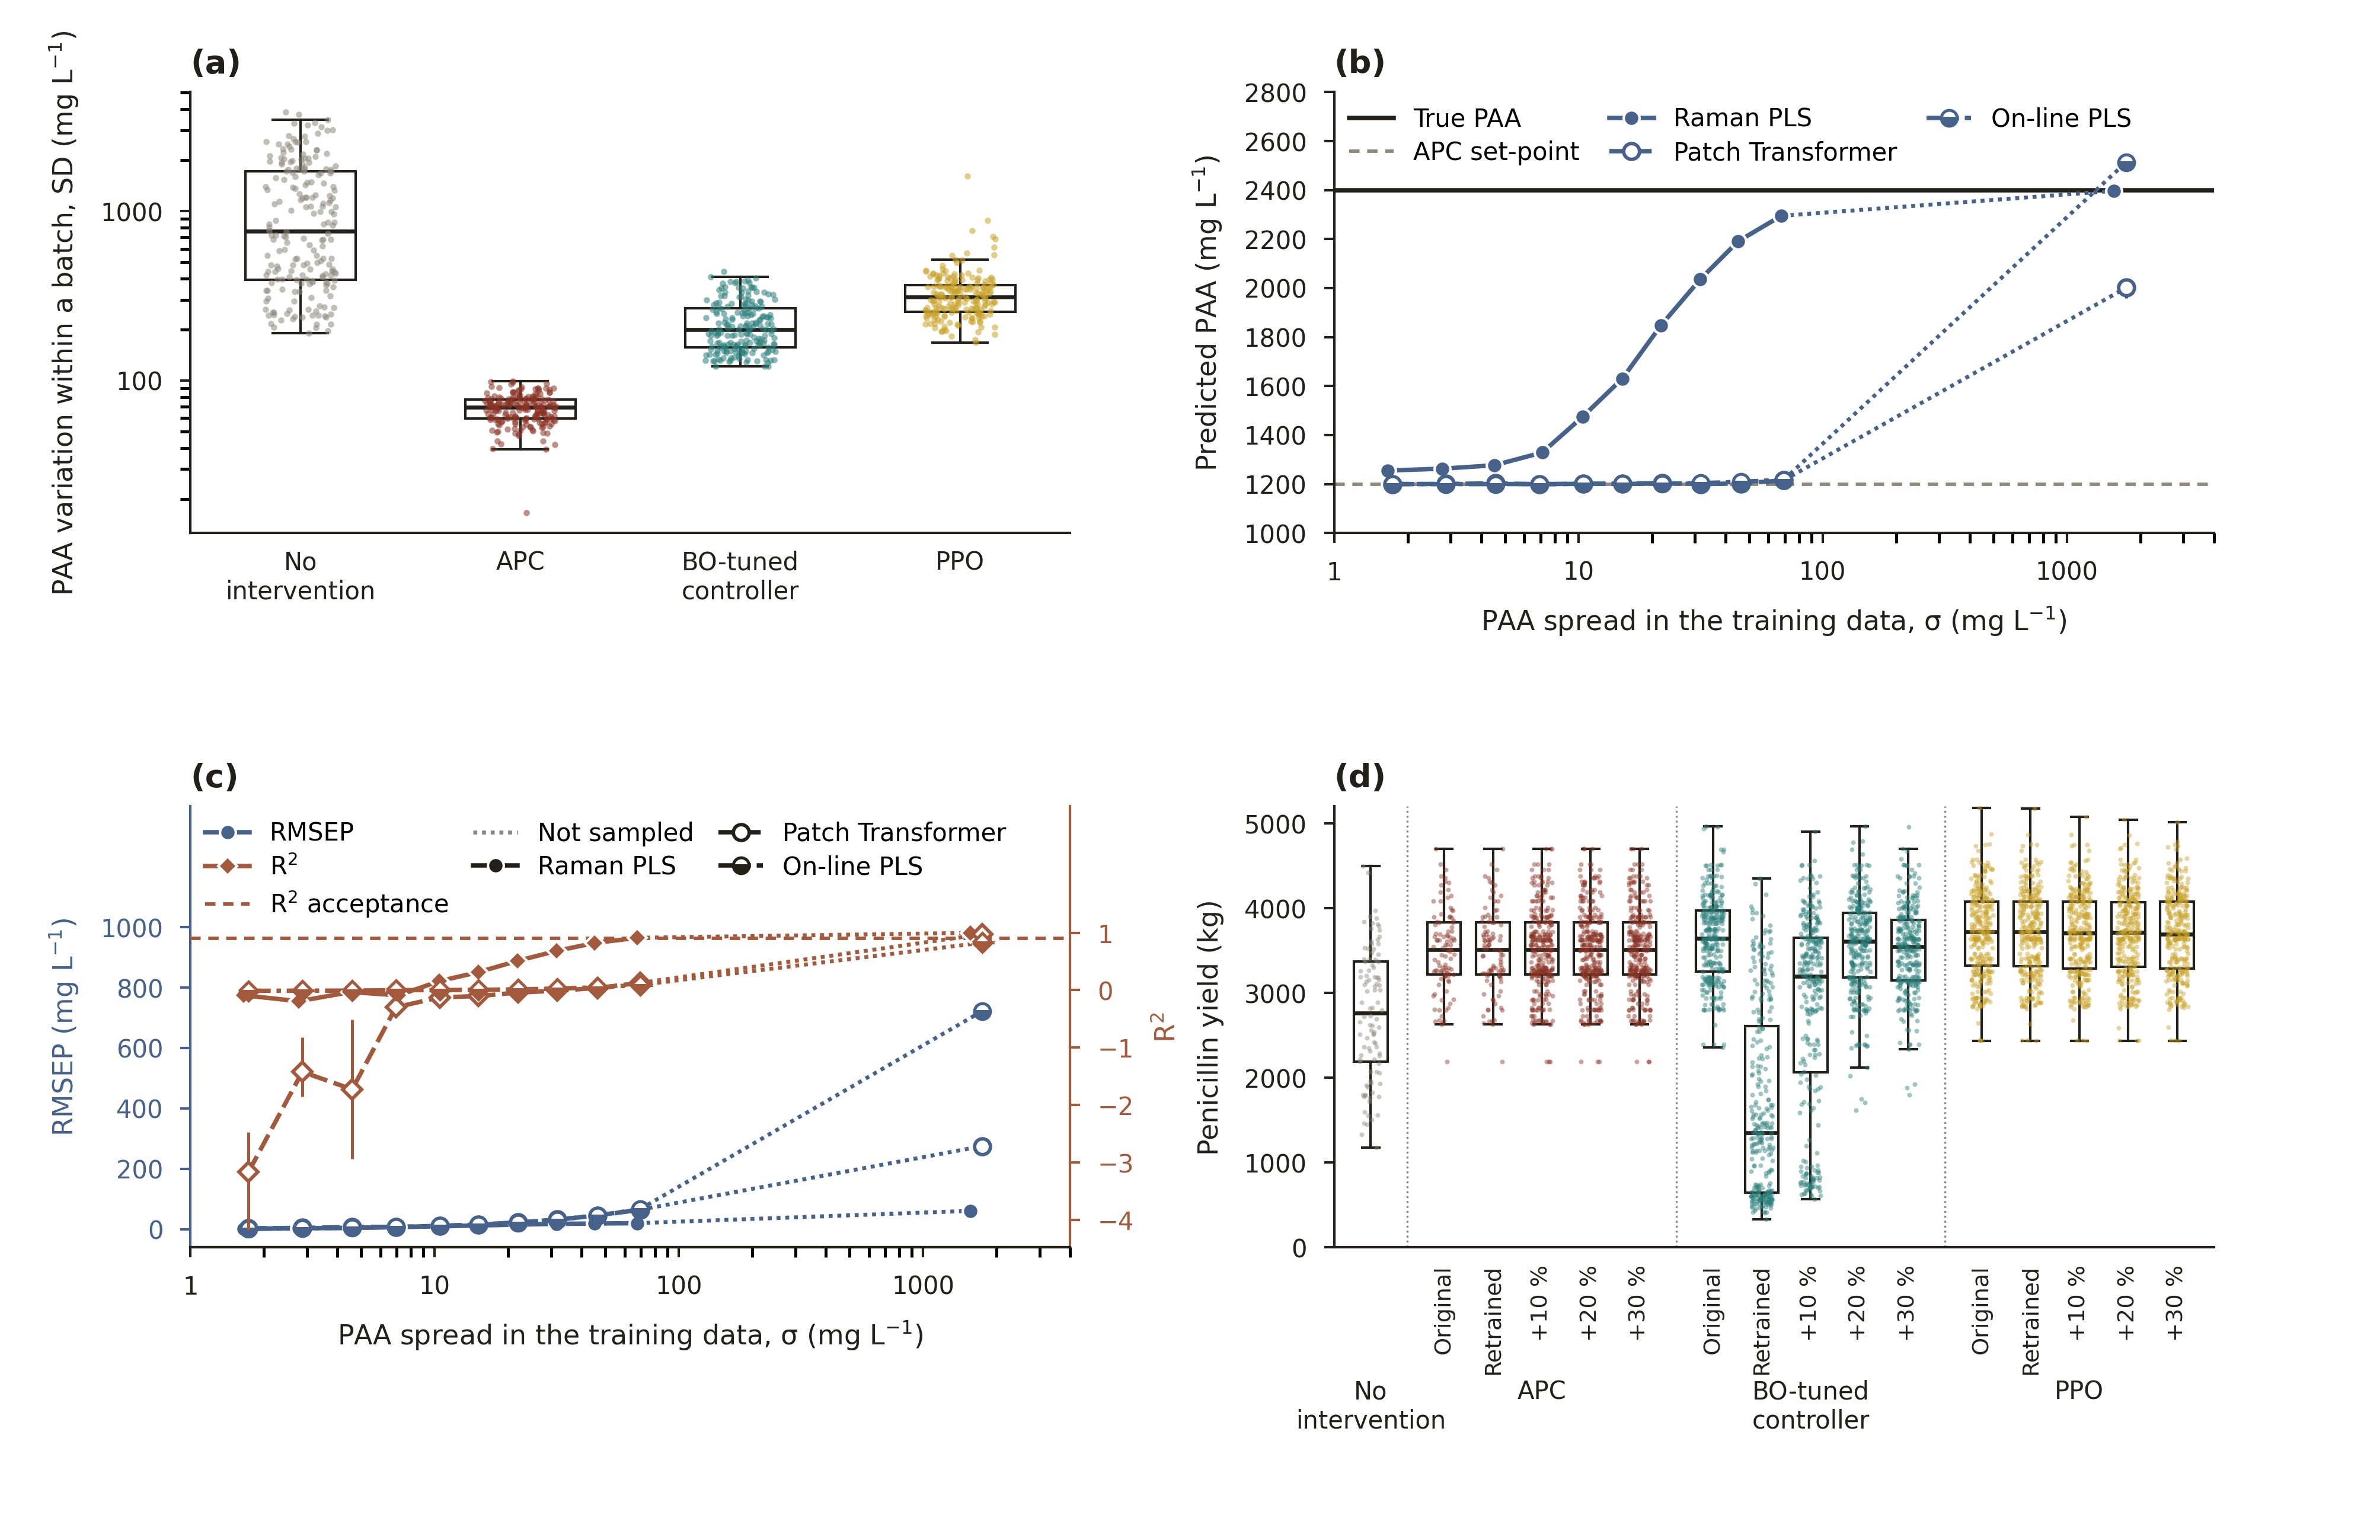

In [6]:
from IPython.display import Image
Image(OUTD + 'fig9.png', width=900)